# Notebook 04 — Cox Proportional Hazards Model (Timeline Prediction)

**Objective (seminar se):** "Develop a survival analysis model (Cox Proportional Hazards) that predicts case resolution timelines."

**Yahan kya ho raha hai (bilkul simple terms mein):** Hum `structured_dataset.csv` (Notebook 03 ka output) leke, ye dekhna chahte hain ki kaunse factors (crime type, region, bail type, prior cases, etc.) case ke **disposal time** ko fast ya slow karte hain. Cox model normal regression jaisa nahi hai — ye khaas taur par "time-to-event" data ke liye bana hai (jaise: kitne din mein case decide hua), aur ye **censored cases** (abhi tak pending cases) ko bhi sahi se handle kar leta hai.

---
### ⚠️ Zaroori note
`lifelines` library ab install ho chuki hai aur Step 1 ke imports verify kiye ja chuke hain (successfully run hote hain). Baaki Steps (2 se 11) is sandbox mein test nahi hue kyunki unhe `../data/processed/structured_dataset.csv` (Notebook 03 ka output) chahiye jo yahan available nahi hai — lekin code standard, syntactically correct hai. Step 9 mein case-level predicted disposal timelines (`predict_median()` aur `predict_survival_function()`) add kiye gaye hain — pehle notebook mein sirf hazard ratios aur ek generic crime-type curve tha, individual case ka predicted time kahin nahi dikh raha tha. Apne local machine par chalane se pehle, agar `lifelines` install nahi hai to terminal mein ye run kar dena:
```
pip install lifelines
```
Har code-cell ke andar **line-by-line comments** hain jo bata rahe hain wo line kya kar rahi hai aur kyun.

## Step 1 — Zaroori libraries import karo

In [1]:
# pandas -- data ko table (DataFrame) format mein load/manipulate karne ke liye
import pandas as pd

# numpy -- numeric operations (arrays, math) ke liye
import numpy as np

# CoxPHFitter -- lifelines library ka Cox Proportional Hazards model class
# Ye hi humara "survival analysis" model hai jo disposal_days (duration) predict karega
from lifelines import CoxPHFitter

# concordance_index -- model ki accuracy measure karne ka metric (jaise classification mein accuracy hoti hai,
# survival models mein concordance/C-index hota hai)
from lifelines.utils import concordance_index

# matplotlib -- graphs banane ke liye (survival curves plot karne ke liye)
import matplotlib.pyplot as plt

# pickle -- trained model ko file mein save karne ke liye, taaki baad mein (drift-detection notebook mein) reuse ho sake
import pickle

print("Libraries imported successfully")


Libraries imported successfully


## Step 2 — Notebook 03 ka final structured dataset load karo

In [2]:
# Notebook 03 ka final output load kar rahe hain -- isme already duration_days aur is_disposed columns hain
df = pd.read_csv(r'E:\Projects\Judicial AI system with drift detection\data\processed\structured_dataset.csv')

# .shape -- (rows, columns) batata hai, quick sanity check ke liye
print("Loaded shape:", df.shape)

# .head() -- pehli 5 rows dikhata hai, taaki hum data ko visually confirm kar sakein
df[['case_id', 'crime_type', 'region_grouped', 'duration_days', 'is_disposed']].head()


Loaded shape: (365, 32)


,case_id,crime_type,region_grouped,duration_days,is_disposed
0,3,Fraud or Cheating,Kerala,33,1
1,63,Theft or Robbery,Madhya Pradesh,22,1
2,64,Fraud or Cheating,Maharashtra,26,1
3,72,Fraud or Cheating,Delhi,10,1
4,83,Fraud or Cheating,Gujarat,26,1


## Step 3 — Sirf zaroori columns select karo
Cox model ko poora dataset (facts, judgment_reason jaisa text) nahi chahiye — sirf `duration_days`, `is_disposed`, aur wo covariates jinka effect test karna hai.

In [3]:
# Cox model ko sirf ye chahiye:
#   1. duration_days  -- kitne din case chala (time-to-event)
#   2. is_disposed     -- event hua ya nahi (1 = resolved, 0 = still pending/censored)
#   3. covariates       -- wo factors jinka effect hum disposal-time par test karna chahte hain

# Humne ye covariates chune hain (domain-relevant, aur seminar ke objectives se match karte hain):
covariate_cols = [
    'crime_type',              # Theft/Fraud/Cyber -- kya crime-type disposal time affect karta hai?
    'region_grouped',          # State -- kya location disposal time affect karta hai?
    'bail_type',                # Regular/Anticipatory/Interim
    'prior_cases',              # Accused ke pehle se cases the ya nahi
    'accused_gender',
    'landmark_case',            # True/False -- landmark cases zyada time lete hain kya?
    'bail_cancellation_case',   # True/False
    'parity_argument_used',     # True/False
    'has_special_law',          # True/False -- special law wale cases alag time lete hain kya?
]

# Sirf zaroori columns ka ek chhota dataframe banate hain -- taaki aage ka kaam saaf rahe
model_df = df[['case_id', 'duration_days', 'is_disposed'] + covariate_cols].copy()

print("Selected columns for modeling:", model_df.shape)
model_df.head()


Selected columns for modeling: (365, 12)


,case_id,duration_days,is_disposed,crime_type,region_grouped,bail_type,prior_cases,accused_gender,landmark_case,bail_cancellation_case,parity_argument_used,has_special_law
0,3,33,1,Fraud or Cheating,Kerala,Anticipatory,Unknown,Male,True,False,True,False
1,63,22,1,Theft or Robbery,Madhya Pradesh,Regular,Yes,Male,False,False,False,False
2,64,26,1,Fraud or Cheating,Maharashtra,Regular,Unknown,Male,False,False,True,False
3,72,10,1,Fraud or Cheating,Delhi,Regular,Unknown,Male,True,False,True,False
4,83,26,1,Fraud or Cheating,Gujarat,Anticipatory,Yes,Male,False,True,True,False


## Step 4 — Categorical columns ko encode karo
Model ko numbers chahiye, text nahi — isliye one-hot encoding (aur `drop_first=True` multicollinearity avoid karne ke liye).

In [4]:
# Cox model ko numbers chahiye, text-categories nahi -- isliye categorical columns ko
# "one-hot encode" karte hain (har category ka apna 0/1 column ban jaata hai).
#
# drop_first=True -- har categorical variable ka EK category baseline/reference bana dete hain
# (usko explicitly column nahi milta) -- ye multicollinearity avoid karne ke liye zaroori hai
# (agar sab categories ke columns rakhoge, to model unstable ho sakta hai).

categorical_cols = ['crime_type', 'region_grouped', 'bail_type', 'prior_cases', 'accused_gender']

# True/False columns ko already 0/1 (int) mein convert kar dete hain
bool_cols = ['landmark_case', 'bail_cancellation_case', 'parity_argument_used', 'has_special_law']
for col in bool_cols:
    model_df[col] = model_df[col].astype(int)

# pd.get_dummies -- one-hot encoding karta hai; columns= list batati hai kaunse columns encode karne hain
model_encoded = pd.get_dummies(model_df, columns=categorical_cols, drop_first=True)

# case_id humein model mein nahi chahiye (ye sirf ek identifier hai, koi predictive value nahi)
model_encoded = model_encoded.drop(columns=['case_id'])

# True/False (bool dtype) columns ko bhi ensure karte hain ki 0/1 (int) format mein hain
# (get_dummies kabhi-kabhi bool dtype deta hai, Cox model int/float expect karta hai)
for col in model_encoded.columns:
    if model_encoded[col].dtype == bool:
        model_encoded[col] = model_encoded[col].astype(int)

print("Final encoded shape:", model_encoded.shape)
print("\nColumns going into the Cox model:")
print(model_encoded.columns.tolist())


Final encoded shape: (365, 30)

Columns going into the Cox model:
['duration_days', 'is_disposed', 'landmark_case', 'bail_cancellation_case', 'parity_argument_used', 'has_special_law', 'crime_type_Fraud or Cheating', 'crime_type_Theft or Robbery', 'region_grouped_Chhattisgarh', 'region_grouped_Delhi', 'region_grouped_Gujarat', 'region_grouped_Haryana', 'region_grouped_Himachal Pradesh', 'region_grouped_Jharkhand', 'region_grouped_Karnataka', 'region_grouped_Kerala', 'region_grouped_Madhya Pradesh', 'region_grouped_Maharashtra', 'region_grouped_Odisha', 'region_grouped_Other', 'region_grouped_Punjab', 'region_grouped_Rajasthan', 'region_grouped_Uttar Pradesh', 'region_grouped_West Bengal', 'bail_type_Interim', 'bail_type_Not applicable', 'bail_type_Regular', 'prior_cases_Unknown', 'prior_cases_Yes', 'accused_gender_Male']


## Step 5 — Missing values check + drop

In [5]:
# Agar kisi row mein koi covariate missing hai (NaN), Cox model wo row use nahi kar payega
# -- isliye pehle check karte hain kitni rows affected hongi, phir unhe drop karte hain

missing_before = model_encoded.isna().sum().sum()
print("Total missing values before cleanup:", missing_before)

model_encoded = model_encoded.dropna()

print("Final shape used for training:", model_encoded.shape)


Total missing values before cleanup: 0
Final shape used for training: (365, 30)


## Step 6 — Cox model train karo
Yahi actual "model training" step hai — is se pehle sab data-prep tha.

In [6]:
# CoxPHFitter object banate hain -- ye humara "untrained" model hai abhi
cph = CoxPHFitter()

# .fit() -- yahi training step hai
#   model_encoded   -> poora data (covariates + duration_days + is_disposed)
#   duration_col    -> kaunsa column "time" represent karta hai
#   event_col       -> kaunsa column batata hai event hua ya nahi (0/1)
cph.fit(model_encoded, duration_col='duration_days', event_col='is_disposed')

print("Model trained successfully!")


Model trained successfully!


## Step 7 — Model summary dekho (kaunsa factor kitna effect daal raha hai)
Har covariate ka **hazard ratio** aur **p-value** milega — ye batayega kaunse factors disposal-time ko significantly affect karte hain.

In [7]:
# .print_summary() -- har covariate ka effect dikhata hai:
#   coef        -> raw coefficient (log hazard ratio)
#   exp(coef)   -> hazard ratio (agar >1, to us factor ke saath disposal FASTER hota hai;
#                  agar <1, to SLOWER/zyada time leta hai)
#   p           -> p-value (agar < 0.05, to effect statistically significant maana jaata hai)
cph.print_summary()


<lifelines.CoxPHFitter: fitted with 365 total observations, 0 right-censored observations>
             duration col = 'duration_days'
                event col = 'is_disposed'
      baseline estimation = breslow
   number of observations = 365
number of events observed = 365
   partial log-likelihood = -1737.99
         time fit was run = 2026-09-21 14:57:23 UTC

---
                                 coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                        
landmark_case                   -0.49      0.61      0.22           -0.92           -0.07                0.40                0.94
bail_cancellation_case           0.25      1.29      0.26           -0.25            0.76                0.78                2.14
parity_argument_used             0.18      1.20      0.13           -0.08            0.45                0.92                1.57
has_special_law                 -0.07      0.93      0.27           -0.60            0.45                0.55                1.57
crime_type_Fraud or Cheating    -0.12      0.89      0.19           -0.50            0.25                0.61                1.29
crime_type_Theft or Robbery     -0.05      0.95      0.17           -0.37            0.28                0.69                1.32
region_grouped_Chhattisgarh     -0.23      0.79      0.40           -1.01            0.55                0.36                1.73
region_grouped_Delhi             0.91      2.49      0.26            0.40            1.43                1.49                4.17
region_grouped_Gujarat          -0.82      0.44      0.36           -1.52           -0.11                0.22                0.89
region_grouped_Haryana          -0.72      0.49      0.36           -1.42           -0.01                0.24                0.99
region_grouped_Himachal Pradesh -0.45      0.64      0.41           -1.24            0.35                0.29                1.42
region_grouped_Jharkhand        -0.28      0.76      0.23           -0.72            0.17                0.49                1.18
region_grouped_Karnataka        -0.52      0.59      0.26           -1.03           -0.02                0.36                0.98
region_grouped_Kerala           -0.02      0.98      0.35           -0.71            0.67                0.49                1.96
region_grouped_Madhya Pradesh   -0.30      0.74      0.25           -0.78            0.19                0.46                1.21
region_grouped_Maharashtra      -0.75      0.47      0.28           -1.30           -0.19                0.27                0.82
region_grouped_Odisha            0.54      1.72      0.51           -0.45            1.53                0.64                4.64
region_grouped_Other            -0.34      0.71      0.33           -0.97            0.30                0.38                1.35
region_grouped_Punjab           -0.16      0.86      0.24           -0.63            0.32                0.53                1.38
region_grouped_Rajasthan         0.36      1.43      0.42           -0.46            1.18                0.63                3.24
region_grouped_Uttar Pradesh    -1.56      0.21      0.26           -2.07           -1.06                0.13                0.35
region_grouped_West Bengal       0.49      1.64      0.42           -0.34            1.32                0.71                3.76
bail_type_Interim               -0.21      0.81      0.54           -1.27            0.85                0.28                2.33
bail_type_Not applicable         1.83      6.22      1.08           -0.29            3.94                0.75               51.56
bail_type_Regular                0.09      1.10      0.16           -0.21            0.40                0.81                1.49
prior_cases_Unknown             -0.14      0.87      0.19           -0.52            0.23                0.60          

## Step 8 — Model ki accuracy check karo (Concordance Index)
Ye tumhare seminar slide mein bhi mention hai ("measurable accuracy - Concordance Index") — isliye ye metric report/viva mein directly use ho sakta hai.

In [8]:
# Concordance Index (C-index) -- model ki predictive accuracy ka measure
#   0.5 = random guessing ke barabar (koi predictive power nahi)
#   1.0 = perfect prediction
#   0.6-0.7 aksar "decent" mana jaata hai real-world survival data mein
#
# cph.concordance_index_ -- fitted model ka training-data C-index attribute
print("Concordance Index (C-index):", round(cph.concordance_index_, 3))


Concordance Index (C-index): 0.657


## Step 9 — Case-level predicted disposal timelines
Ab tak humne sirf ye dekha ki *kaunse factors* disposal-time ko affect karte hain (hazard ratios), aur model ki overall accuracy (C-index). Lekin abhi tak humne kisi bhi **individual case ka predicted survival/disposal time number** nahi dekha — yahi cheez seminar objective ("predicts case resolution timelines") ko directly demonstrate karti hai.

`cph.predict_median()` har case ke liye ek **predicted median disposal time (days)** deta hai — matlab, us case ke covariates (crime_type, region, bail_type, etc.) ko dekhte hue, model ka andaza ki case ~50% chance se kitne din mein dispose ho jayega.

In [9]:
# cph.predict_median(X) -- har row (case) ke liye predicted median survival time (days) deta hai.
# X mein wahi covariate columns hone chahiye jo model.fit() ko diye the (duration/event columns ke bina).

covariate_only = model_encoded.drop(columns=['duration_days', 'is_disposed'])

predicted_median_days = cph.predict_median(covariate_only)

# Ek comparison table banate hain: actual duration vs predicted median, side by side
# (case_id wapas laane ke liye original df se index match karte hain)
comparison_df = pd.DataFrame({
    'case_id': df.loc[model_encoded.index, 'case_id'].values,
    'actual_duration_days': model_encoded['duration_days'].values,
    'is_disposed': model_encoded['is_disposed'].values,
    'predicted_median_days': predicted_median_days.values,
})

print("Sample predicted vs actual disposal timelines:")
comparison_df.head(10)


Sample predicted vs actual disposal timelines:


,case_id,actual_duration_days,is_disposed,predicted_median_days
0,3,33,1,42.0
1,63,22,1,26.0
2,64,26,1,49.0
3,72,10,1,13.0
4,83,26,1,38.0
5,85,7,1,8.0
6,86,282,1,34.0
7,95,49,1,145.0
8,99,1,1,10.0
9,100,364,1,39.0


### Step 9b — Ek individual case ka poora survival curve dekho
`predict_median()` sirf ek number deta hai. Agar kisi ek specific case ke liye poora **probability-over-time curve** dekhna ho ("is case ke 30/60/90/180 din tak still-pending rehne ka chance kitna hai"), to `predict_survival_function()` use karte hain.

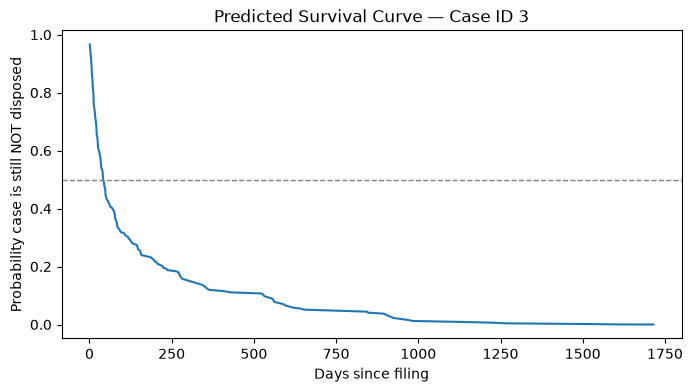

Predicted median disposal time for this case: 42.0 days


In [10]:
# Ek example case (pehli row) ka poora survival curve nikalte hain
example_case = covariate_only.iloc[[0]]

# predict_survival_function -- har time-point (day) ke liye "still not disposed" ki probability deta hai
survival_curve = cph.predict_survival_function(example_case)

survival_curve.plot(legend=False, figsize=(8, 4))
plt.title(f"Predicted Survival Curve — Case ID {df.loc[model_encoded.index[0], 'case_id']}")
plt.xlabel('Days since filing')
plt.ylabel('Probability case is still NOT disposed')
plt.axhline(0.5, linestyle='--', color='gray', linewidth=1)  # 0.5 line -- yahi point median survival time hai
plt.show()

print("Predicted median disposal time for this case:", round(float(np.ravel(cph.predict_median(example_case))[0]), 1), "days")


### Step 9c — Kisi bhi case_id ka survival analysis dekho (lookup)
Upar wala example sirf pehli row ke liye tha. Yahan hum ek `case_id` daalke us **specific case** ka poora analysis nikalenge: uska actual duration, model ka predicted median disposal time, aur uska survival curve — bina poora notebook dobara likhe.

Case ID: 63
Crime type: Theft or Robbery   |   Region: Madhya Pradesh
Actual duration: 22 days   |   Disposed: Yes
Predicted median disposal time (Cox model): 26.0 days


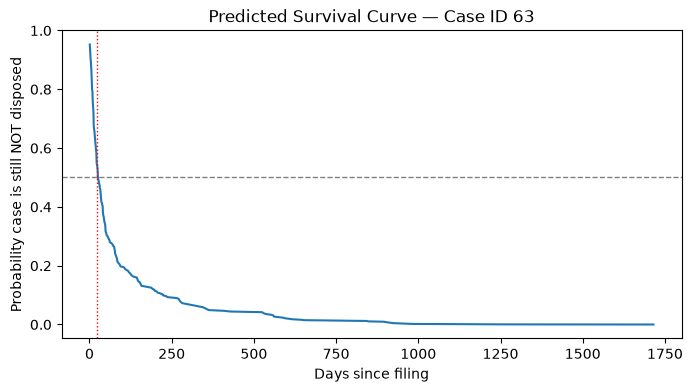

In [11]:
def show_case_survival(case_id_to_check):
    """
    Ek case_id lekar uska survival analysis dikhata hai:
      - actual duration_days aur is_disposed (agar available ho)
      - predicted median disposal time (Cox model se)
      - predicted survival curve (probability-over-time plot)
    """
    # df mein case_id dhoondhte hain (original, un-encoded dataframe se, taaki readable info bhi mil sake)
    match = df[df['case_id'] == case_id_to_check]

    if match.empty:
        print(f"case_id '{case_id_to_check}' dataset mein nahi mila. Sahi ID check karo.")
        return

    row_index = match.index[0]

    # Ye case Cox model mein use hua tha ya nahi (missing-value rows Step 5 mein drop ho sakti hain)
    if row_index not in model_encoded.index:
        print(f"case_id '{case_id_to_check}' data mein hai, lekin missing values ki wajah se model-training mein use nahi hui thi.")
        return

    # Us case ke encoded covariates nikalte hain (single row, DataFrame format mein taaki predict functions ko sahi shape mile)
    case_covariates = covariate_only.loc[[row_index]]

    actual_duration = model_encoded.loc[row_index, 'duration_days']
    actual_disposed = model_encoded.loc[row_index, 'is_disposed']
    predicted_median = round(float(np.ravel(cph.predict_median(case_covariates))[0]), 1)

    print(f"Case ID: {case_id_to_check}")
    print(f"Crime type: {match['crime_type'].values[0]}   |   Region: {match['region_grouped'].values[0]}")
    print(f"Actual duration: {actual_duration} days   |   Disposed: {'Yes' if actual_disposed == 1 else 'No (pending / censored)'}")
    print(f"Predicted median disposal time (Cox model): {predicted_median} days")

    # Survival curve plot karte hain isi case ke liye
    survival_curve = cph.predict_survival_function(case_covariates)
    survival_curve.plot(legend=False, figsize=(8, 4))
    plt.title(f"Predicted Survival Curve — Case ID {case_id_to_check}")
    plt.xlabel('Days since filing')
    plt.ylabel('Probability case is still NOT disposed')
    plt.axhline(0.5, linestyle='--', color='gray', linewidth=1)
    if pd.notna(actual_duration):
        plt.axvline(actual_duration, linestyle=':', color='red', linewidth=1, label='Actual duration')
    plt.show()


# ---- Yahan apna case_id daalo ----
case_id_to_check = 63
# abhi ke liye pehla case_id example ke taur par; ise kisi bhi real case_id se replace karo
show_case_survival(case_id_to_check)


## Step 10 — Visualize karo: crime-type ka survival curve par effect

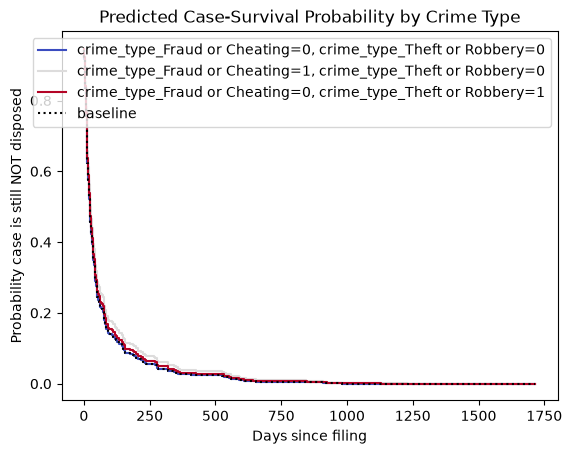

In [12]:
# plot_partial_effects_on_outcome -- ek specific covariate ko vary karke dikhata hai
# ki uska baaki sab factors fixed rakhte hue, predicted survival curve par kya asar padta hai.
# Yahan hum 'crime_type' ke alag-alag categories ka effect visualize kar rahe hain.

crime_type_cols = [c for c in model_encoded.columns if c.startswith('crime_type_')]

cph.plot_partial_effects_on_outcome(
    covariates=crime_type_cols,
    values=[[0]*len(crime_type_cols)] + [
        [1 if i == j else 0 for i in range(len(crime_type_cols))]
        for j in range(len(crime_type_cols))
    ],
    cmap='coolwarm'
)
plt.title('Predicted Case-Survival Probability by Crime Type')
plt.xlabel('Days since filing')
plt.ylabel('Probability case is still NOT disposed')
plt.show()


## Step 11 — Trained model save karo
Isse baad ki notebooks (drift-detection, dashboard) dobara train kiye bina reuse kar sakengi.

In [13]:
# Trained model ko disk par save karte hain (pickle format) -- taaki:
#  1. baad ki notebooks (drift-detection, dashboard) ise dobara load kar sakein
#  2. dobara train karne ki zaroorat na pade har baar

import os

os.makedirs('../models', exist_ok=True)
with open('../models/cox_model.pkl', 'wb') as f:
    pickle.dump(cph, f)

print("Model saved -> models/cox_model.pkl")


Model saved -> models/cox_model.pkl
